# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">Introduction to DenseNet-121</p>

DenseNet-121 is a deep learning architecture designed for image classification and other tasks like segmentation. It belongs to the family of convolutional neural networks (CNNs) and is characterized by its unique connectivity pattern. Here’s an overview of its key features and architecture:
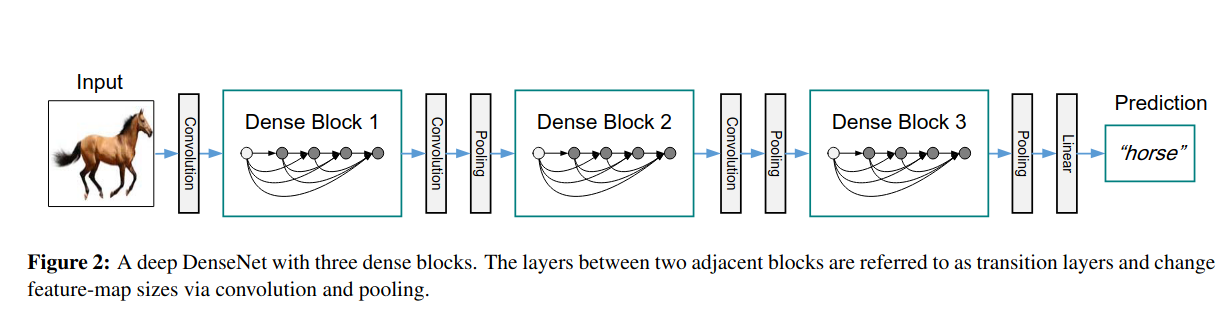

### **Key Features**

1. **Dense Connectivity**:
   - Unlike traditional CNNs where each layer connects only to the next layer, in DenseNet, each layer is connected to every other layer in a feed-forward manner. This means that the output of each layer is fed into all subsequent layers.
   - This dense connectivity allows for improved feature reuse and gradient flow, which can help in training deeper networks without suffering from the vanishing gradient problem.

2. **Reduced Parameters**:
   - DenseNet architectures use fewer parameters than traditional CNNs because they do not need to learn redundant features. Each layer receives inputs from all preceding layers, effectively reducing the overall number of parameters.

3. **Improved Gradient Flow**:
   - The dense connections help gradients flow more easily during backpropagation, which facilitates the training of deeper networks. This is particularly beneficial for tasks that require a large number of layers.

4. **Bottleneck Layers**:
   - DenseNet-121 uses bottleneck layers to reduce the number of feature maps before applying a convolution. This further decreases computational cost and improves efficiency.

5. **Compression**:
   - DenseNet architectures often include transition layers that compress the feature maps and reduce the spatial dimensions, making the network more efficient.

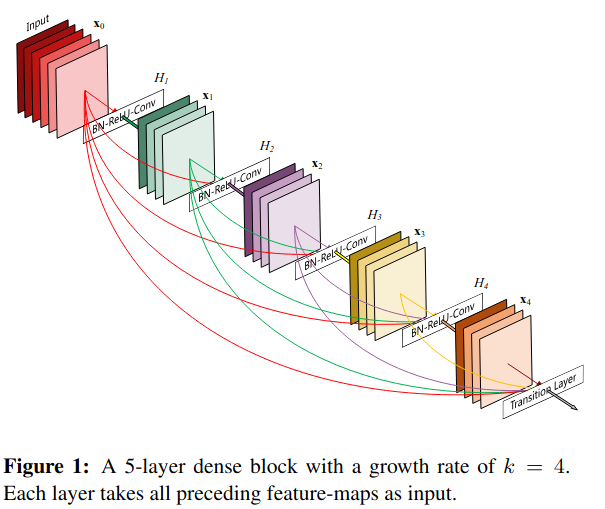

### **Applications**

DenseNet-121 has been widely used in various applications, including:

- **Image Classification**: Recognizing objects in images.
- **Object Detection**: Identifying and localizing objects within an image.
- **Segmentation**: Segmenting an image into different parts (e.g., foreground and background).
- **Transfer Learning**: Fine-tuning the model on new datasets for specific tasks.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, metrics

import matplotlib.pyplot as plt

import os
import warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">Dataset Overview for Brain Tumor Classification</p>

### 1. **Description of Brain Tumors**
- **Definition**: A brain tumor is a mass of abnormal cells in the brain, which can be benign (noncancerous) or malignant (cancerous). Growth within the confined space of the skull can lead to increased intracranial pressure, causing potential brain damage and life-threatening conditions.

### **Total Images**: 7,023 MRI images of human brains.
### **Class Distribution**:
  - Glioma
  - Meningioma
  - Pituitary Tumor
  - No Tumor

### **Training and Testing Data**:
  - **Training Set**: 5,712 images across all classes.
  - **Test Set**: 1,311 images across all classes.

In [2]:
# Getting the trainig set
train_set = keras.preprocessing.image_dataset_from_directory(
    '/kaggle/input/brain-tumor-mri-dataset/Training',
    seed=123,
    interpolation='nearest',
    batch_size=32,
    image_size=(256,256)
)


Found 5712 files belonging to 4 classes.


In [3]:
# Getting the testing set
test_set = keras.preprocessing.image_dataset_from_directory(
    '/kaggle/input/brain-tumor-mri-dataset/Testing',
    seed=123,
    interpolation='nearest',
    batch_size=32,
    image_size=(256,256)
)

Found 1311 files belonging to 4 classes.


In [4]:
class_names = train_set.class_names
print(class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


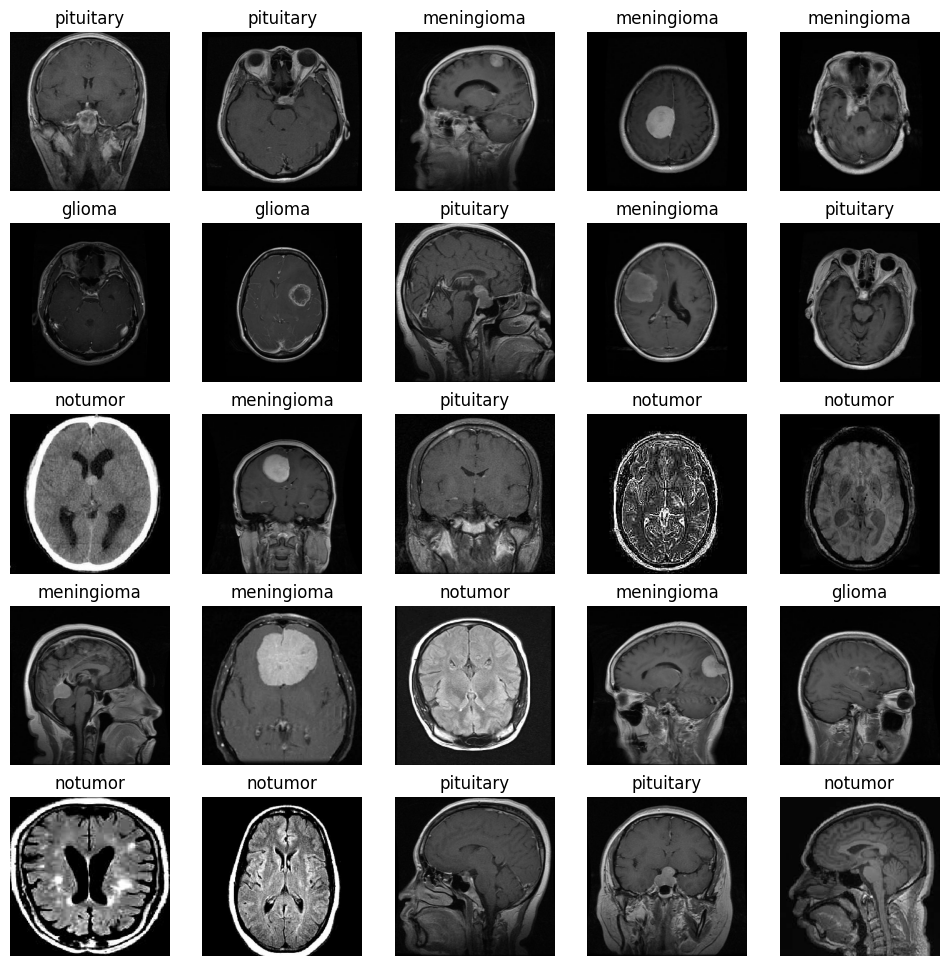

In [5]:
plt.figure(figsize=(12,12))
for img, label in train_set.take(1):
    for i in range(25):
        plt.subplot(5,5,i+1)
        plt.imshow(img[i])
        plt.title(class_names[label[i]])
        plt.axis('off')

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_set = train_set.cache().prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">Architecture Overview</p>
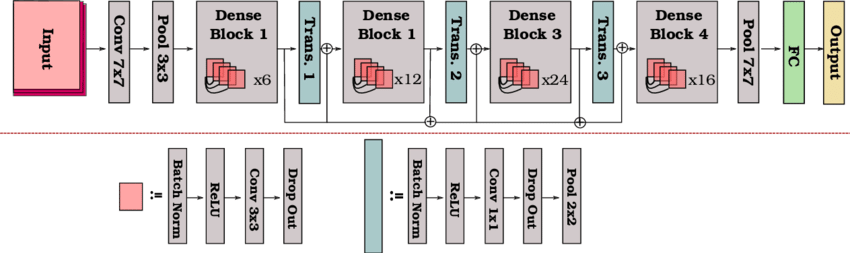
1. **Input Layer**:
   - Accepts an image input, typically of size \(224 \times 224 \times 3\) (height, width, channels).

2. **Convolutional Layers**:
   - The initial layer consists of a convolutional layer followed by batch normalization and ReLU activation.

3. **Dense Blocks**:
   - DenseNet-121 includes several dense blocks. Each dense block contains multiple convolutional layers where each layer outputs feature maps that are fed into the next layer.
   - The number of layers in DenseNet-121 is 121, hence the name.

4. **Transition Layers**:
   - After each dense block, a transition layer is applied that consists of a batch normalization layer, a convolutional layer, and an average pooling layer. This helps to reduce the feature map size and number of channels.

5. **Global Average Pooling**:
   - After the final dense block, a global average pooling layer reduces the spatial dimensions to a single value per feature map.

6. **Fully Connected Layer**:
   - The final layer is a fully connected (dense) layer that outputs the class probabilities (typically using softmax for multi-class classification).

# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">Bottleneck Layer</p>
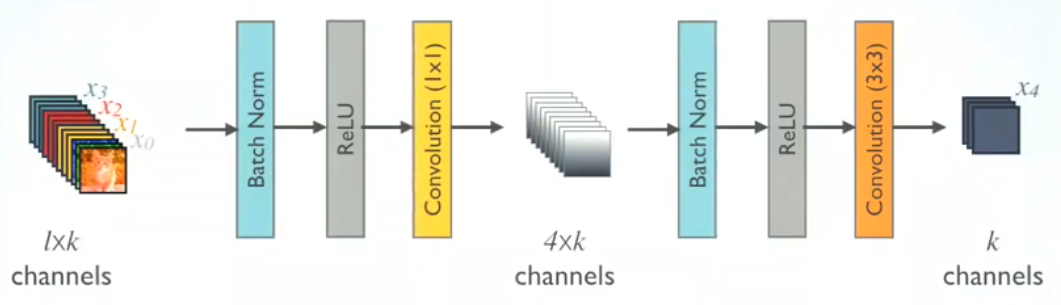

The provided function defines a **bottleneck layer** for a DenseNet-like architecture. Here's a breakdown of its components and functionality:

1. **Function Definition**:
   ```python
   def bottleneck_layer(x, filters, strides=1):
   ```
   - `x`: Input tensor from the previous layer.
   - `filters`: Number of output filters for the convolutional layers.
   - `strides`: Strides for the convolution operations (default is 1).

2. **Skip Connection**:
   ```python
   skip_connection = x
   ```
   - This line saves the input tensor `x` to be used later for a skip connection. This allows the layer to add its output back to the input, promoting feature reuse.

3. **Batch Normalization and ReLU Activation**:
   - The first batch normalization and ReLU activation:
   ```python
   x = layers.BatchNormalization()(x)
   x = layers.ReLU()(x)
   ```
   - These operations normalize the inputs and introduce non-linearity, improving convergence during training.

4. **1x1 Convolution**:
   ```python
   x = layers.Conv2D(4*filters, kernel_size=1, strides=strides, padding='same')(x)
   ```
   - A 1x1 convolution reduces the dimensionality of the input. The number of filters is increased to `4 * filters`, which helps capture more features.

5. **Second Batch Normalization and ReLU Activation**:
   - Again, normalization and activation are applied:
   ```python
   x = layers.BatchNormalization()(x)
   x = layers.ReLU()(x)
   ```

6. **3x3 Convolution**:
   ```python
   x = layers.Conv2D(filters, kernel_size=3, strides=strides, padding='same')(x)
   ```
   - A 3x3 convolution is then applied to extract features from the feature maps produced by the previous layers.

7. **Concatenation**:
   ```python
   x = layers.Concatenate()([x, skip_connection])
   ```
   - The output from the 3x3 convolution is concatenated with the original input (the skip connection). This allows the network to retain both the newly learned features and the original features, facilitating better gradient flow and feature reuse.

8. **Return**:
   ```python
   return x
   ```
   - The function returns the output tensor `x`, which now contains the combined features from both the convolutional layers and the skip connection.

This bottleneck layer effectively combines convolutional operations with skip connections to enhance feature extraction and promote deeper network training. It helps reduce the number of parameters while maintaining the model's ability to learn complex features, a key characteristic of DenseNet architectures.

In [7]:
# Creating Bottleneck layer (Dense layer)
def bottleneck_layer(x,filters,strides=1):
    skip_connection = x
    # BN-ReLU-Conv(1×1)-BN-ReLU-Conv(3×3)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(4*filters,kernel_size=1,strides=strides,padding='same')(x)
    
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters,kernel_size=3,strides=strides,padding='same')(x)
    
    x = layers.Concatenate()([x,skip_connection])
    return x

# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">Transition Layer</p>
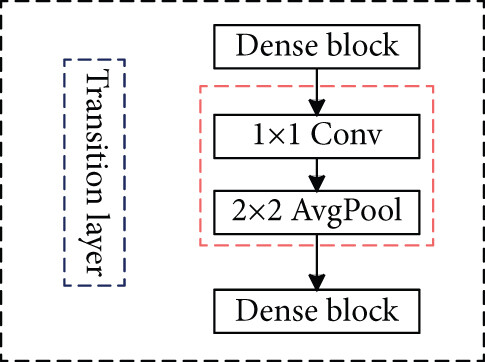

The `transition_layer` function implements a transition layer for a DenseNet architecture. Here’s a detailed explanation of its components and functionality:


1. **Function Definition**:
   ```python
   def transition_layer(x):
   ```
   - The function takes an input tensor `x`, which is typically the output from a previous dense block.

2. **Batch Normalization**:
   ```python
   x = layers.BatchNormalization()(x)
   ```
   - This layer normalizes the input, which helps stabilize the learning process and improves convergence.

3. **ReLU Activation**:
   ```python
   x = layers.ReLU()(x)
   ```
   - After normalization, the ReLU activation function is applied to introduce non-linearity, allowing the model to learn more complex patterns.

4. **1x1 Convolution**:
   ```python
   x = layers.Conv2D(keras.backend.int_shape(x)[-1]//2, kernel_size=1, strides=1, padding='same')(x)
   ```
   - A 1x1 convolution is used to reduce the number of feature maps by half. This helps decrease the computational load and the number of parameters in the network while retaining important features.

5. **Average Pooling**:
   ```python
   x = layers.AvgPool2D(2, strides=2, padding='same')(x)
   ```
   - An average pooling layer is applied with a pool size of 2 and a stride of 2. This operation reduces the spatial dimensions of the feature maps by half, downsampling the input while retaining essential information.

6. **Return**:
   ```python
   return x
   ```
   - The function returns the output tensor after applying batch normalization, ReLU activation, the 1x1 convolution, and the average pooling.

The `transition_layer` function serves to reduce the number of feature maps and downsample the spatial dimensions of the input tensor. By combining batch normalization, ReLU activation, and convolutional operations, it helps maintain the flow of information while decreasing complexity, making it an integral part of the DenseNet architecture that facilitates efficient learning and improves overall model performance.

In [8]:
# Creating transition layer (pooling layer)
def transition_layer(x):
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(keras.backend.int_shape(x)[-1]//2,kernel_size=1,strides=1,padding='same')(x)
    
    x = layers.AvgPool2D(2,strides=2,padding='same')(x)
    return x

# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">Dense Block</p>

The `dense_block` function creates a dense block for a DenseNet architecture, where multiple bottleneck layers are stacked together. Here’s a detailed explanation of its components and functionality:

1. **Function Definition**:
   ```python
   def dense_block(x, repetition=1, growth_rate=32):
   ```
   - The function takes three parameters:
     - `x`: The input tensor to the dense block.
     - `repetition`: The number of bottleneck layers to be included in the dense block (default is 1).
     - `growth_rate`: The number of filters to be used in each bottleneck layer (default is 32).

2. **Loop for Bottleneck Layers**:
   ```python
   for _ in range(repetition):
       x = bottleneck_layer(x, growth_rate)
   ```
   - A loop runs for the specified number of repetitions. In each iteration, the `bottleneck_layer` function is called with the current tensor `x` and the specified `growth_rate`.
   - The output of each bottleneck layer becomes the input for the next bottleneck layer, effectively stacking them. This stacking of layers allows the network to learn increasingly complex features.

3. **Return**:
   ```python
   return x
   ```
   - The function returns the output tensor `x`, which now contains the features learned from all the bottleneck layers in the dense block.


The `dense_block` function constructs a series of bottleneck layers, facilitating feature extraction and enhancing the model’s ability to learn from data. By stacking multiple bottleneck layers, it allows for efficient reuse of features while maintaining a manageable number of parameters, a key feature of DenseNet architectures. The flexibility to adjust the number of repetitions and growth rate provides customization for different tasks and datasets.

In [9]:
# Creating dense block
def dense_block(x,repetition=1,growth_rate=32):
    for _ in range(repetition):
        x = bottleneck_layer(x,growth_rate)
    return x

# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">DenseNet-B121 Architecture</p>
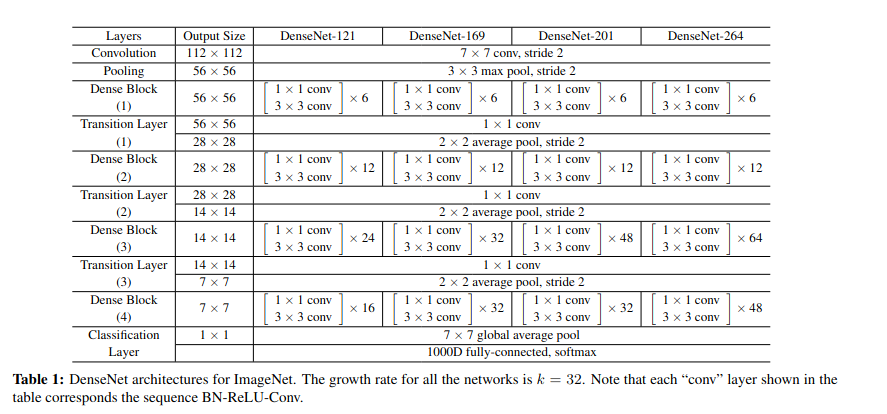


The `densenetb121` function defines a DenseNet-121 architecture using Keras. Here’s a detailed breakdown of the components and functionality:


1. **Function Definition**:
   ```python
   def densenetb121(input_shape, num_classes, growth_rate=32):
   ```
   - **Parameters**:
     - `input_shape`: The shape of the input images (e.g., height, width, channels).
     - `num_classes`: The number of output classes for classification.
     - `growth_rate`: The number of filters to be added per layer (default is 32).

2. **Input Layer**:
   ```python
   inputs = layers.Input(shape=input_shape)
   ```
   - Defines the input layer of the model, where the input shape corresponds to the shape of the training images.

3. **Initial Layer**:
   ```python
   x = layers.BatchNormalization()(inputs)
   x = layers.ReLU()(x)
   x = layers.Conv2D(64, kernel_size=7, strides=2, padding='same')(x)
   ```
   - Applies batch normalization and ReLU activation to the inputs.
   - A 7x7 convolutional layer is applied with 64 filters, a stride of 2 for downsampling, and padding set to 'same' to maintain the spatial dimensions.

4. **Pooling Layer**:
   ```python
   x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
   ```
   - A max pooling layer with a pool size of 3 and stride of 2 is applied to reduce the spatial dimensions of the feature maps.

5. **Dense and Transition Layers**:
   - **First Dense Block**:
     ```python
     x = dense_block(x, 6, growth_rate)
     x = transition_layer(x)
     ```
     - The first dense block consists of 6 bottleneck layers, followed by a transition layer to reduce feature map size.
   
   - **Second Dense Block**:
     ```python
     x = dense_block(x, 12, growth_rate)
     x = transition_layer(x)
     ```
     - The second dense block has 12 bottleneck layers, followed by another transition layer.
   
   - **Third Dense Block**:
     ```python
     x = dense_block(x, 24, growth_rate)
     x = transition_layer(x)
     ```
     - The third dense block consists of 24 bottleneck layers, again followed by a transition layer.
   
   - **Last Dense Block**:
     ```python
     x = dense_block(x, 16, growth_rate)
     ```
     - The final dense block contains 16 bottleneck layers without a subsequent transition layer.

6. **Global Average Pooling Layer**:
   ```python
   x = layers.GlobalAveragePooling2D()(x)
   ```
   - This layer averages the spatial dimensions of the feature maps, reducing each feature map to a single value. This helps condense the information before the output layer.

7. **Output Layer**:
   ```python
   outputs = layers.Dense(num_classes, activation='softmax')(x)
   ```
   - A dense layer with `num_classes` units and a softmax activation function is added to produce the final class probabilities for classification.

8. **Model Creation**:
   ```python
   model = models.Model(inputs, outputs)
   return model
   ```
   - Constructs the Keras model by specifying the input and output tensors and returns the model object.

The `densenetb121` function constructs a DenseNet-121 architecture that includes a series of dense blocks and transition layers, facilitating efficient feature extraction and classification. This architecture is designed to handle image classification tasks, leveraging the strengths of dense connectivity to improve gradient flow and parameter efficiency.

In [10]:
# Creating DenseNet-B121
def densenetb121(input_shape,num_classes,growth_rate=32): 
    # Input layer
    inputs = layers.Input(shape=input_shape)
    
    # Initial layer
    x = layers.BatchNormalization()(inputs)
    x = layers.ReLU()(x)
    x = layers.Conv2D(64,kernel_size=7,strides=2,padding='same')(x)
    
    # Pooling layer
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
    
    # First dense and transition layer
    x = dense_block(x,6,growth_rate)
    x = transition_layer(x)
    
    # second dense and transition layer
    x = dense_block(x,12,growth_rate)
    x = transition_layer(x)
    
    # Third dense and transition layer
    x = dense_block(x,24,growth_rate)
    x = transition_layer(x)
    
    # Last dense layer
    x = dense_block(x,16,growth_rate)
    
    # Global average pooling layer
    x = layers.GlobalAveragePooling2D()(x)
    
    # Output layer
    outputs = layers.Dense(num_classes,activation='softmax')(x)
    
    model = models.Model(inputs,outputs)
    return model
    

In [11]:
model = densenetb121(input_shape=(256,256,3),num_classes=len(class_names))

In [12]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │         12 │ input_layer[0][0] │
│ (BatchNormalizatio… │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      9,472 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ max_pooling2d[0]… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      8,320 │ re_lu_1[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     36,896 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ conv2d_2[0][0],   │
│ (Concatenate)       │ 96)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        384 │ concatenate[0][0] │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     12,416 │ re_lu_3[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat

 Total params: 7,047,504 (26.88 MB)

 Trainable params: 6,966,026 (26.57 MB)

 Non-trainable params: 81,478 (318.27 KB)



In [13]:
keras.utils.plot_model(model,show_shapes=True,expand_nested=True)

In [14]:
model.compile(
    optimizer=tf.optimizers.Adam(epsilon=0.05),
    loss='sparse_categorical_crossentropy',
    metrics=[metrics.SparseCategoricalAccuracy(name='accuracy')]
             
)

In [15]:
history = model.fit(train_set,
                    validation_data=test_set,
                    epochs=64,
                    batch_size=32)

Epoch 1/64


I0000 00:00:1746979932.144272      72 service.cc:145] XLA service 0x7a1770023c70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1746979932.144346      72 service.cc:153]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1746980017.315304      72 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_1381', 4 bytes spill stores, 4 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_1376', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_22', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_21', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fus

178/179 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.6386 - loss: 0.9881

I0000 00:00:1746980135.449448      72 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'input_reduce_slice_fusion_58', 12 bytes spill stores, 12 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_48', 4 bytes spill stores, 4 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_49', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_6', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_22', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_21', 8 bytes spill stores, 8 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_548', 8 bytes spill st

179/179 ━━━━━━━━━━━━━━━━━━━━ 283s 765ms/step - accuracy: 0.6392 - loss: 0.9867 - val_accuracy: 0.3753 - val_loss: 1.3935
Epoch 2/64
179/179 ━━━━━━━━━━━━━━━━━━━━ 38s 210ms/step - accuracy: 0.7504 - loss: 0.6602 - val_accuracy: 0.4233 - val_loss: 1.3060
Epoch 3/64
179/179 ━━━━━━━━━━━━━━━━━━━━ 38s 211ms/step - accuracy: 0.8179 - loss: 0.4997 - val_accuracy: 0.7262 - val_loss: 0.8325
Epoch 4/64
179/179 ━━━━━━━━━━━━━━━━━━━━ 37s 209ms/step - accuracy: 0.8555 - loss: 0.4068 - val_accuracy: 0.6232 - val_loss: 0.9795
Epoch 5/64
179/179 ━━━━━━━━━━━━━━━━━━━━ 37s 209ms/step - accuracy: 0.8870 - loss: 0.3266 - val_accuracy: 0.5591 - val_loss: 1.6579
Epoch 6/64
179/179 ━━━━━━━━━━━━━━━━━━━━ 37s 209ms/step - accuracy: 0.9038 - loss: 0.2655 - val_accuracy: 0.5934 - val_loss: 1.3835
Epoch 7/64
179/179 ━━━━━━━━━━━━━━━━━━━━ 37s 208ms/step - accuracy: 0.9291 - loss: 0.2029 - val_accuracy: 0.5256 - val_loss: 4.1123
Epoch 8/64
179/179 ━━━━━━━━━━━━━━━━━━━━ 37s 209ms/step - accuracy: 0.9453 - loss: 0.1545 - va

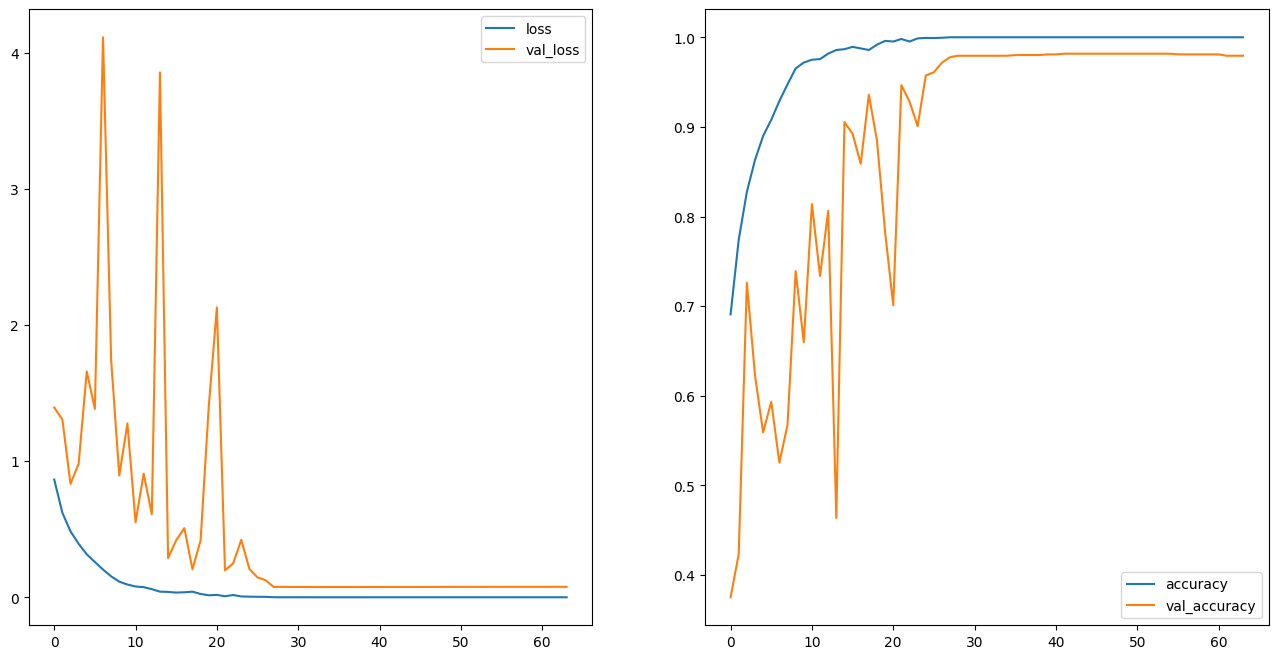

In [16]:
import pandas as pd
plt.figure(figsize=(16,8))

plt.subplot(121)
hist_df = pd.DataFrame(history.history)
hist_df.loc[:,['loss','val_loss']].plot(ax=plt.gca())


plt.subplot(122)
hist_df.loc[:,['accuracy','val_accuracy']].plot(ax=plt.gca())

plt.show()

In [17]:
loss,accuracy = model.evaluate(test_set)

print('Loss:',loss)
print('Accuracy:',accuracy)

41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.9874 - loss: 0.0454
Loss: 0.07705742865800858
Accuracy: 0.9794050455093384


# <p style="font-size: 36px; background-color: #87CEEB; color: white; padding: 10px 20px; width: 95%; border-radius: 15px; text-align: center; margin: 0 auto; font-weight: bold;">Conclusion</p>

In this notebook, we explored the DenseNet-121 architecture, a powerful convolutional neural network designed for image classification tasks. We discussed the core components of DenseNet, including bottleneck layers and dense blocks, which facilitate efficient feature extraction through dense connectivity. The bottleneck layer reduces the number of parameters while maintaining essential features, and the transition layer helps manage the spatial dimensions of feature maps.

The construction of DenseNet-121 involves a series of dense blocks interspersed with transition layers, culminating in a global average pooling layer followed by a softmax output layer for classification. This architecture enhances gradient flow and promotes feature reuse, making it highly effective for tasks such as brain tumor classification in medical imaging.

Overall, DenseNet-121 stands out for its ability to learn complex representations with fewer parameters, making it an ideal choice for deep learning applications in various domains, particularly where data efficiency and model performance are critical.